In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def r_switch(S, S_half, rho, r_min):
    return (1-r_min) / (np.exp((S-S_half)/rho) + 1) + r_min

# def cascade_size(gamma, S, K, rng):
#     m = min(gamma*S/K, 0.999)
#     assert(m<1)
#     Z_sum = 0
#     Z = 1
#     while Z != 0:
#         Z_sum += Z
#         Z = rng.poisson(m*Z)
#     return Z_sum

def cascade_size(gamma, S, K, rng, k=1):
    m = min(gamma*S/K, 0.999)
    Z_sum = 0
    Z = 1
    while Z != 0:
        Z_sum += Z
        Z = rng.binomial(k*Z, m/k)   # Z sweeps, each Binomial(k, m/k): same mean m, less spread
    return Z_sum

def L(S, sweeps, r, rng):
    return min(S, rng.binomial(sweeps, r))

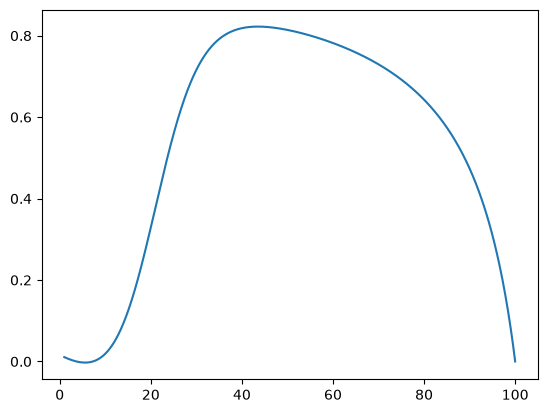

In [ ]:
S_half = 20
gamma = 0.03
rho = 5
r_min = 0.1
K = 3/(1-r_min)
S_high = int(round(K*(1-r_min)/gamma))
T=100000
S_dist = np.linspace(1, 100, 1000)
f_theory = 1 - r_switch(S_dist, S_half, rho, r_min)/(1-(S_dist*gamma/K))
rng = np.random.default_rng(123)
plt.plot(S_dist, f_theory)
plt.show()

In [ ]:
S_hist = np.zeros(T)
S = 1
S_hist[0] = S
for i in range(T-1):
    g = 1
    r_val = r_switch(S, S_half, rho, r_min)
    sweeps = cascade_size(gamma, S, K, rng)
    L_val = L(S, sweeps, r_val, rng)
    ds = g - L_val
    S += ds
    S_hist[i+1] = S


100


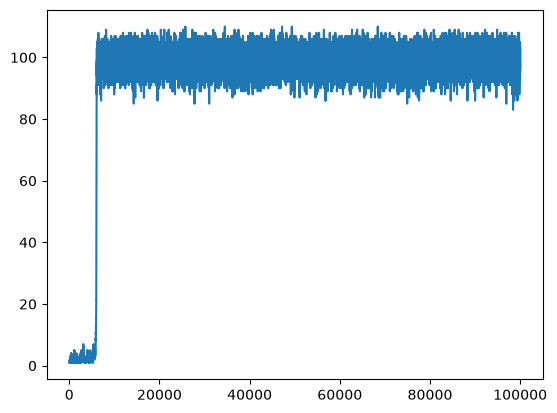

In [5]:
n = np.linspace(0, T, T)
plt.plot(n, S_hist)
print(S_high)

In [33]:
#Overview
#State Variables: S, F
#Parameters: gamma, a, b, S_c, p
#Intermediates: r, c, G, E, j, q

def q(F, p, q0, p_c, F_c):
    return q0*(1- p/p_c)*(1- (F-1)/(F_c-1))

def r(q, F):
    return q**F

def c(r, S, S_c):
    return r/(1-S/S_c)

def G(b, r, S, S_c):
    return b*(1-r)/(1-S/S_c)

def E(j, gamma, S, S_c):
    return j*gamma/(1-S/S_c)

def j(a, F):
    return a*(F-1)

def dS(c):
    return 1 - c

def dF(c, F, G, E, S):
    return ((1-c)*(1-F) + G - E)/S

def rhs(S, F, params):
    gamma, a, b, S_c, p, p_c, F_c, q0 = params
    q_val = q(F, p, q0, p_c, F_c)
    r_val = r(q_val, F)
    c_val = c(r_val, S, S_c)
    G_val = G(b, r_val, S, S_c)
    j_val = j(a,F)
    E_val = E(j_val, gamma, S, S_c)
    dS_val = dS(c_val)
    dF_val = dF(c_val, F, G_val, E_val, S)
    return dS_val, dF_val

In [211]:
gamma = 0.03
a = 10
b = 1.1
S_c = 110
p = 0.1
p_c = 0.41
F_c = 10
q0 = 0.97
params = (gamma, a, b, S_c, p, p_c, F_c, q0)   # same order as the unpack line

S_low = S_c*(1-q0)

In [212]:
S_vals = np.linspace(1, 109, 100)
F_vals = np.linspace(1, 10, 100)
S_grid, F_grid = np.meshgrid(S_vals, F_vals)
dS_grid, dF_grid = rhs(S_grid, F_grid, params)

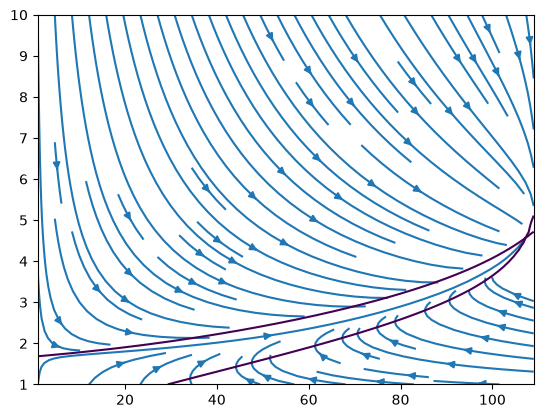

In [213]:
plt.streamplot(S_grid, F_grid, dS_grid, dF_grid )
plt.contour(S_grid, F_grid, dS_grid, levels=[0])
plt.contour(S_grid, F_grid, dF_grid, levels=[0])

In [214]:
q_val = q(F_vals, p, q0, p_c, F_c)
r_val = r(q_val, F_vals)
Y1 = b*(1-r_val)
Y2 = gamma*a*(F_vals-1)

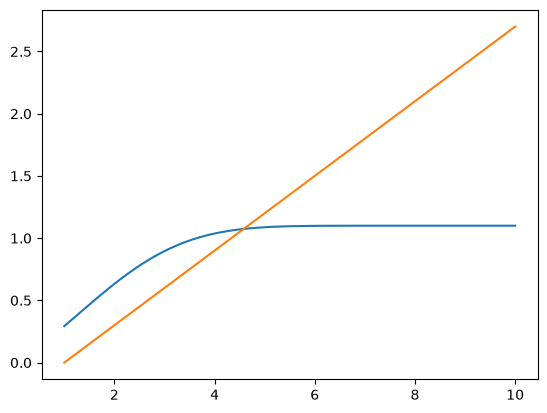

In [215]:
plt.plot(F_vals, Y1)
plt.plot(F_vals, Y2)

In [208]:
n_steps = 200000          # total time = n_steps*dt = 20,000 arrivals
dt = 0.1
rng = np.random.default_rng(1)

# Noise sizes (variance per arrival)
sigma_S = 6               # extinction noise; Poisson guess gives 1, heavy tails push it up
sigma_P = 3               # island noise (G, E) on the patch count

# Starts: all at the low fixed point, so every rise is noise-driven
n_starts = 6
S0 = np.full(n_starts, 8.4)
F0 = np.full(n_starts, 1.28)

S_hist = np.zeros((n_steps, n_starts))
F_hist = np.zeros((n_steps, n_starts))
S_hist[0], F_hist[0] = S0, F0

for i in range(n_steps-1):
    S, F = S_hist[i], F_hist[i]
    dS_v, dF_v = rhs(S, F, params)

    xi1 = rng.standard_normal(n_starts)      # shared: extinctions hit S and F
    xi2 = rng.standard_normal(n_starts)      # F only: islands made and eaten
    coef = (1 - F)/S                         # one extra extinction (dS = dP = -1) raises F by (F-1)/S
    kick_S = sigma_S*np.sqrt(dt)*xi1
    kick_F = (coef*sigma_S*xi1 + (sigma_P/S)*xi2)*np.sqrt(dt)

    S_new = S + dt*dS_v + kick_S             # Euler-Maruyama: drift ~ dt, noise ~ sqrt(dt)
    F_new = F + dt*dF_v + kick_F

    S_hist[i+1] = np.clip(S_new, 1, 0.99*S_c)   # keep inside the region the equations allow
    F_hist[i+1] = np.clip(F_new, 1, F_c - 0.01)

Text(0, 0.5, 'F')

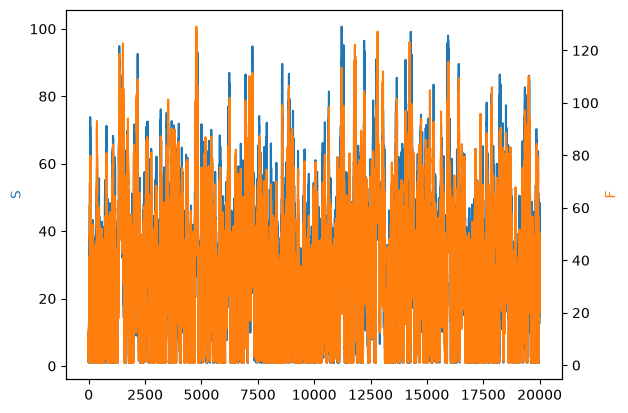

In [209]:
X = np.linspace(0, n_steps*dt, n_steps)
k = 0                             # which trajectory (column) to look at
fig, ax = plt.subplots()
ax.plot(X, S_hist[:, k], color="C0")
ax.set_ylabel("S", color="C0")
twin = ax.twinx()
twin.plot(X, F_hist[:, k]*S_hist[:, k], color="C1")
twin.set_ylabel("F", color="C1")

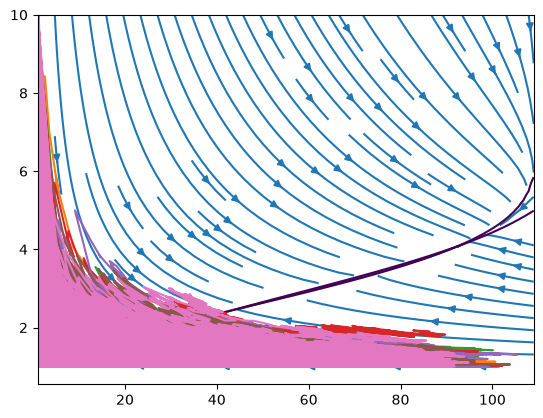

In [210]:
plt.streamplot(S_grid, F_grid, dS_grid, dF_grid )
plt.contour(S_grid, F_grid, dS_grid, levels=[0])
plt.contour(S_grid, F_grid, dF_grid, levels=[0])
plt.plot(S_hist, F_hist)